<a href="https://colab.research.google.com/github/ChronosXV/Metodologia_grupo2/blob/noelia_modelado/Metodologia_1_Grupo_2_Modelado_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###Trabajo Práctico Final

**Materia:**

Metodología de la Investigación

**Alumnos:**

- Gisela Martínez
- Noelia Cualina
- José Leonardo Carabajal
- Javier Carabajal


**Objetivo:**

Desarrollar y evaluar modelos de Machine Learning para predecir niveles de demanda en la red de subtes de CABA.

Período de estudio: 2017–2021.



Enfoque: cuantitativo, descriptivo y predictivo.



Metodología: CRISP-DM.



Variable objetivo: nivel_demanda, con categorías baja, media y alta.



Variable base para construir el objetivo: pax_total.



Variables predictoras: línea, estación, franja horaria, año, mes, día de la semana y condición de día hábil.



Evaluación: accuracy, precision, recall, F1-score y matriz de confusión.

### 1. Introducción y objetivo del modelado

El presente trabajo constituye la continuación del análisis exploratorio y la preparación de datos realizados sobre los registros históricos de pasajeros de la red de subterráneos de la Ciudad Autónoma de Buenos Aires durante el período 2017–2021.

En esta etapa se propone desarrollar y evaluar modelos de Machine Learning que permitan clasificar y predecir niveles de demanda de pasajeros, utilizando información temporal y espacial disponible en los registros históricos.

Para ello, se utilizará el conjunto de datos previamente procesado y agrupado por fecha, línea, estación y franja horaria, tomando como referencia la cantidad total de pasajeros registrados (pax_total).

A partir de esta variable se construirán tres categorías de demanda: baja, media y alta, que constituirán la variable objetivo (nivel_demanda) del problema de clasificación supervisada.

Los modelos utilizarán características como la línea, la estación, la franja horaria y variables temporales derivadas de la fecha. La cantidad total de pasajeros no será incorporada como variable predictora, dado que se utilizará para construir la variable objetivo.

Se compararán distintos algoritmos de clasificación mediante métricas de evaluación apropiadas, prestando especial atención a la identificación de situaciones de alta demanda.

Asimismo, se contempla la aplicación de técnicas de aprendizaje no supervisado como análisis complementario, con el propósito de identificar posibles agrupamientos en los patrones de demanda.

El desarrollo seguirá las etapas de modelado y evaluación de la metodología CRISP-DM, buscando obtener resultados reproducibles que permitan contrastar la hipótesis planteada y formular recomendaciones basadas en evidencia cuantitativa.
####

**Hipótesis de investigación**

Los episodios de alta demanda en la red de subtes de CABA durante el período 2017–2021 no se distribuyen de manera uniforme, sino que presentan patrones asociados a factores temporales y espaciales. Se espera que la probabilidad de registrar niveles elevados de demanda varíe según la estación, la línea, el día de la semana y la franja horaria, permitiendo identificar y predecir situaciones de alta demanda a partir de estas características.


### 2. Importación de librerías y carga del dataset procesado.

En esta sección se importan las bibliotecas necesarias para el procesamiento de datos, la construcción de modelos de Machine Learning y la evaluación de resultados. Posteriormente, se carga el conjunto de datos consolidado durante la etapa de preparación, que servirá como base para el modelado predictivo.

In [1]:
# Manipulación y análisis de datos
import pandas as pd
import numpy as np
import os

# Visualización de resultados
import matplotlib.pyplot as plt
import seaborn as sns

# Preparación de datos
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Modelos de clasificación supervisada
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Evaluación de modelos
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score
)

# Aprendizaje no supervisado
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Acceso a Google Drive
from google.colab import drive

print("Librerías importadas correctamente.")

Librerías importadas correctamente.


In [2]:
# Montar Google Drive
drive.mount("/content/drive")

# Definir la ruta del dataset procesado
ruta_carpeta = "/content/drive/MyDrive/Datos_csv/"
ruta_limpios = os.path.join(ruta_carpeta, "datos_limpios")

ruta_dataset = os.path.join(
    ruta_limpios,
    "historico_2017_2021_dim.parquet"
)

# Cargar el dataset consolidado
df = pd.read_parquet(ruta_dataset)

# Verificar la carga
print("Dataset cargado correctamente.")
print(f"Cantidad de registros: {df.shape[0]:,}")
print(f"Cantidad de columnas: {df.shape[1]}")

Mounted at /content/drive
Dataset cargado correctamente.
Cantidad de registros: 653,619
Cantidad de columnas: 6


In [3]:
display(df.head())

,fecha,linea,estacion,franja_horaria_num,franja_horaria,pax_total
0,2017-11-27,D,9 DE JULIO,5,Noche,535.0
1,2017-11-28,D,9 DE JULIO,1,Madrugada,9.0
2,2017-11-28,D,9 DE JULIO,2,Pico mañana,1922.0
3,2017-11-28,D,9 DE JULIO,3,Media mañana,4345.0
4,2017-11-29,D,9 DE JULIO,2,Pico mañana,1722.0


In [4]:
# Verificar estructura y tipos de datos del dataset
print("Información general del dataset:")
df.info()

print("\nValores nulos por columna:")
print(df.isnull().sum())

Información general del dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 653619 entries, 0 to 653618
Data columns (total 6 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   fecha               653619 non-null  object 
 1   linea               653619 non-null  object 
 2   estacion            653619 non-null  object 
 3   franja_horaria_num  653619 non-null  int32  
 4   franja_horaria      653619 non-null  object 
 5   pax_total           653619 non-null  float64
dtypes: float64(1), int32(1), object(4)
memory usage: 27.4+ MB

Valores nulos por columna:
fecha                 0
linea                 0
estacion              0
franja_horaria_num    0
franja_horaria        0
pax_total             0
dtype: int64


### 3. Construcción de variables predictoras.

En esta etapa se preparan las variables que serán utilizadas como características de entrada para los modelos de Machine Learning.

A partir del conjunto de datos consolidado, se conservarán las variables espaciales y temporales disponibles, como la línea, la estación y la franja horaria. Además, se construirán nuevas variables a partir de la fecha, con el propósito de representar patrones asociados al comportamiento de la demanda de pasajeros.

Las variables derivadas serán:

*  Año: permite identificar variaciones de demanda entre los distintos años del período analizado.
*  Mes: permite representar posibles patrones estacionales.
*  Día de la semana: permite identificar diferencias de demanda entre lunes y domingo.
*  Fin de semana: permite distinguir sábados y domingos del resto de los días.


La variable pax_total se conservará únicamente para la posterior construcción de la variable objetivo nivel_demanda, correspondiente a las categorías baja, media y alta.

De esta manera, se busca que los modelos aprendan relaciones entre las características temporales y espaciales y los niveles de demanda, evitando incorporar directamente como predictor la cantidad de pasajeros que se desea clasificar.

In [5]:
# Crear una copia del dataset para el modelado
df_modelo = df.copy()

# Convertir la columna fecha a tipo datetime
df_modelo["fecha"] = pd.to_datetime(
    df_modelo["fecha"],
    format="%Y-%m-%d",
    errors="raise"
)

# Construir variables temporales
df_modelo["anio"] = df_modelo["fecha"].dt.year
df_modelo["mes"] = df_modelo["fecha"].dt.month
df_modelo["dia_semana"] = df_modelo["fecha"].dt.dayofweek

# Identificar fines de semana: sábado (5) y domingo (6)
df_modelo["fin_semana"] = (
    df_modelo["dia_semana"] >= 5
).astype(int)

# Visualizar los primeros registros
display(df_modelo.head())

print("\nDimensiones del dataset:", df_modelo.shape)

,fecha,linea,estacion,franja_horaria_num,franja_horaria,pax_total,anio,mes,dia_semana,fin_semana
0,2017-11-27,D,9 DE JULIO,5,Noche,535.0,2017,11,0,0
1,2017-11-28,D,9 DE JULIO,1,Madrugada,9.0,2017,11,1,0
2,2017-11-28,D,9 DE JULIO,2,Pico mañana,1922.0,2017,11,1,0
3,2017-11-28,D,9 DE JULIO,3,Media mañana,4345.0,2017,11,1,0
4,2017-11-29,D,9 DE JULIO,2,Pico mañana,1722.0,2017,11,2,0



Dimensiones del dataset: (653619, 10)


In [6]:
# Seleccionar las variables predictoras
variables_predictoras = [
    "linea",
    "estacion",
    "franja_horaria_num",
    "anio",
    "mes",
    "dia_semana"
]

# Crear el conjunto de características
X = df_modelo[variables_predictoras].copy()

# Verificar las variables seleccionadas
print("Variables predictoras:")
print(X.columns.tolist())

print("\nDimensiones de X:", X.shape)

display(X.head())

Variables predictoras:
['linea', 'estacion', 'franja_horaria_num', 'anio', 'mes', 'dia_semana']

Dimensiones de X: (653619, 6)


,linea,estacion,franja_horaria_num,anio,mes,dia_semana
0,D,9 DE JULIO,5,2017,11,0
1,D,9 DE JULIO,1,2017,11,1
2,D,9 DE JULIO,2,2017,11,1
3,D,9 DE JULIO,3,2017,11,1
4,D,9 DE JULIO,2,2017,11,2


### 4. Definición de la variable objetivo nivel_demanda.

Para el desarrollo de los modelos de clasificación supervisada, se construirá una variable objetivo denominada nivel_demanda, que permitirá clasificar los registros históricos de pasajeros en tres categorías: baja, media y alta demanda.

Esta clasificación se realizará a partir de la variable pax_total, que representa la cantidad total de pasajeros registrada para cada combinación de fecha, línea, estación y franja horaria.

Se propone utilizar un criterio basado en cuantiles, dividiendo la distribución de pasajeros en tres grupos mediante los percentiles 33,33 y 66,67. Este procedimiento permitirá establecer umbrales reproducibles a partir de la distribución observada.

Para evitar fugas de información, los umbrales definitivos se calcularán exclusivamente sobre el conjunto de entrenamiento, después de realizar la separación temporal de los datos. Posteriormente, se aplicarán los mismos límites al conjunto de prueba.

La variable pax_total no se utilizará como característica predictora, ya que constituye la información a partir de la cual se define la variable objetivo.

Es importante señalar que los niveles establecidos representan categorías relativas de demanda de pasajeros, utilizadas como aproximación para identificar situaciones potenciales de congestión, y no mediciones directas de ocupación o saturación de las estaciones.

In [7]:
# Separación temporal preliminar del dataset
# Entrenamiento: 2017 a 2020
# Prueba: 2021

df_train = df_modelo[
    df_modelo["anio"] <= 2020
].copy()

df_test = df_modelo[
    df_modelo["anio"] == 2021
].copy()

# Verificar la cantidad de registros
print("Registros de entrenamiento:", len(df_train))
print("Registros de prueba:", len(df_test))

print("\nDistribución porcentual:")
print(
    f"Entrenamiento: {len(df_train) / len(df_modelo) * 100:.2f}%"
)

Registros de entrenamiento: 541247
Registros de prueba: 112372

Distribución porcentual:
Entrenamiento: 82.81%


In [8]:
# Calcular los cuantiles únicamente con datos de entrenamiento
cuantiles = df_train["pax_total"].quantile([1/3, 2/3])

# Mostrar los valores obtenidos
print("Cuantiles de pax_total (2017-2020):")
print(cuantiles)

Cuantiles de pax_total (2017-2020):
0.333333     354.0
0.666667    1825.0
Name: pax_total, dtype: float64


**Interpretación de los cuantiles obtenidos**

A partir de los registros correspondientes al conjunto de entrenamiento (2017–2020), se calcularon los percentiles 33,33 y 66,67 de la variable `pax_total`, obteniendo los siguientes resultados:

| Percentil | Pasajeros | Interpretación |
|---|---:|---|
| 33,33 % | 354 | Límite entre demanda baja y media |
| 66,67 % | 1.825 | Límite entre demanda media y alta |

Estos valores permiten establecer tres niveles de demanda:

- **Demanda baja:** registros con hasta 354 pasajeros.
- **Demanda media:** registros con más de 354 y hasta 1.825 pasajeros.
- **Demanda alta:** registros con más de 1.825 pasajeros.

Los umbrales se definieron utilizando exclusivamente los datos de entrenamiento y se aplicarán posteriormente al conjunto de prueba (2021), manteniendo el mismo criterio de clasificación.

Es importante destacar que estas categorías representan niveles relativos de demanda según la distribución histórica de pasajeros, y no umbrales operativos de congestión establecidos por la capacidad de las estaciones.

In [9]:
# Obtener los umbrales calculados con entrenamiento
umbral_bajo = cuantiles.loc[1/3]
umbral_alto = cuantiles.loc[2/3]

# Función para clasificar la demanda de pasajeros
def clasificar_demanda(pasajeros):
    """
    Clasifica la cantidad de pasajeros en tres niveles de demanda:
    Baja, Media o Alta.

    Utiliza los umbrales calculados a partir de los cuantiles
    33,33 % y 66,67 % del conjunto de entrenamiento (2017-2020).

    Parámetros:
        pasajeros: cantidad total de pasajeros del registro.

    Retorna:
        str: categoría de demanda correspondiente.
    """
    if pasajeros <= umbral_bajo:
        return "Baja"
    elif pasajeros <= umbral_alto:
        return "Media"
    else:
        return "Alta"

# Aplicar los mismos umbrales a entrenamiento y prueba
df_train["nivel_demanda"] = (
    df_train["pax_total"].apply(clasificar_demanda)
)

df_test["nivel_demanda"] = (
    df_test["pax_total"].apply(clasificar_demanda)
)

# Verificar la distribución de las categorías
print("Distribución de demanda - Entrenamiento:")
print(df_train["nivel_demanda"].value_counts())

print("\nDistribución de demanda - Prueba:")
print(df_test["nivel_demanda"].value_counts())

Distribución de demanda - Entrenamiento:
nivel_demanda
Media    180453
Baja     180441
Alta     180353
Name: count, dtype: int64

Distribución de demanda - Prueba:
nivel_demanda
Baja     54101
Media    42326
Alta     15945
Name: count, dtype: int64


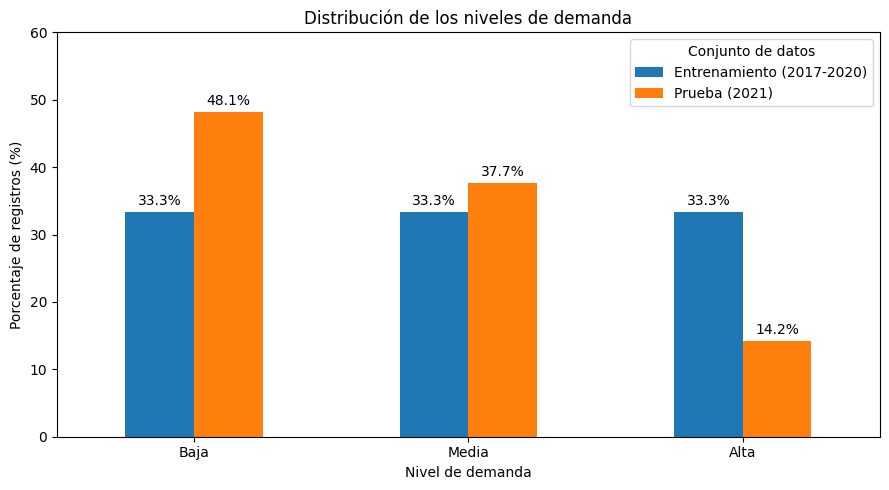

In [11]:
# Comparar la distribución porcentual de los niveles de demanda
orden_niveles = ["Baja", "Media", "Alta"]

# Calcular porcentajes por conjunto
porcentaje_train = (
    df_train["nivel_demanda"]
    .value_counts(normalize=True)
    .reindex(orden_niveles)
    .mul(100)
)

porcentaje_test = (
    df_test["nivel_demanda"]
    .value_counts(normalize=True)
    .reindex(orden_niveles)
    .mul(100)
)

# Preparar los datos para el gráfico
df_distribucion = pd.DataFrame({
    "Entrenamiento (2017-2020)": porcentaje_train,
    "Prueba (2021)": porcentaje_test
})

# Visualizar la comparación
ax = df_distribucion.plot(
    kind="bar",
    figsize=(9, 5),
    rot=0
)

ax.set_title("Distribución de los niveles de demanda")
ax.set_xlabel("Nivel de demanda")
ax.set_ylabel("Porcentaje de registros (%)")
ax.legend(title="Conjunto de datos")

# Mostrar porcentajes sobre cada barra
for contenedor in ax.containers:
    ax.bar_label(contenedor, fmt="%.1f%%", padding=3)

plt.ylim(0, 60)
plt.tight_layout()
plt.show()


**Interpretación de la distribución de los niveles de demanda**

A partir de los umbrales definidos mediante los cuantiles del conjunto de entrenamiento, se construyó la variable objetivo nivel_demanda, clasificando los registros en tres categorías: baja, media y alta.

En el conjunto de entrenamiento (2017–2020), las categorías presentan una distribución prácticamente equilibrada, con aproximadamente un tercio de los registros en cada nivel. Este resultado es consistente con el criterio de clasificación basado en terciles.

En cambio, en el conjunto de prueba (2021), se observa una distribución diferente: **el 48,1 % de los registros corresponde a demanda baja**, **el 37,7 % a demanda media** y solamente **el 14,2 % a demanda alta**.

Esta diferencia evidencia un cambio en la distribución relativa de los niveles de demanda entre ambos períodos, utilizando los mismos umbrales de clasificación. Si bien podría estar relacionada con las modificaciones en la movilidad urbana durante la pandemia de COVID-19, los resultados obtenidos no permiten establecer por sí solos una relación causal.

Estos hallazgos serán considerados posteriormente durante la evaluación de los modelos predictivos, especialmente al analizar su capacidad para identificar correctamente los registros de alta demanda.

### 5. Preparación de datos y separación temporal.

####5.1 Preparación de datos para el entrenamiento

En esta etapa se preparan los conjuntos de datos que serán utilizados para entrenar y evaluar los modelos de clasificación supervisada.

Se mantiene la separación temporal definida anteriormente, utilizando los registros de **2017–2020 para entrenamiento** y los correspondientes a **2021 para prueba**. Este criterio permite evaluar la capacidad de los modelos para clasificar registros de un período posterior al utilizado durante el aprendizaje.

Las variables predictoras se agruparán en una matriz de características (`X`), mientras que la variable objetivo `nivel_demanda` se almacenará por separado (`y`).

Debido a que algunas características, como la línea y la estación, son categóricas, será necesario aplicar técnicas de codificación para convertirlas en representaciones compatibles con los algoritmos de Machine Learning.

Estas transformaciones se ajustarán exclusivamente con los datos de entrenamiento y se aplicarán posteriormente al conjunto de prueba, evitando fugas de información.

La variable `pax_total` no será incorporada como predictor, dado que fue utilizada para definir los niveles de demanda.

####5.2 Separar características predictoras y variable objetivo

In [12]:
# Conjunto de entrenamiento (2017-2020)
X_train = df_train[variables_predictoras].copy()
y_train = df_train["nivel_demanda"].copy()

# Conjunto de prueba (2021)
X_test = df_test[variables_predictoras].copy()
y_test = df_test["nivel_demanda"].copy()

# Verificar las dimensiones
print("Entrenamiento:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nPrueba:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

# Verificar las categorías de la variable objetivo
print("\nCategorías de demanda:")
print(y_train.unique())

Entrenamiento:
X_train: (541247, 6)
y_train: (541247,)

Prueba:
X_test: (112372, 6)
y_test: (112372,)

Categorías de demanda:
['Media' 'Baja' 'Alta']


#### 5.3 Codificación y transformación de variables predictoras

Antes de entrenar los modelos de Machine Learning, es necesario preparar las variables predictoras para que puedan ser procesadas correctamente por los algoritmos.

En nuestro conjunto de datos contamos con variables categóricas, como la línea y la estación de subte, y variables temporales, como el año, mes, día de la semana y franja horaria.

Para realizar estas transformaciones se utilizarán las siguientes técnicas:

* **One-Hot Encoding:** permite transformar las variables categóricas en columnas binarias (0 y 1), evitando que los algoritmos interpreten sus categorías como valores numéricos ordenados. Se aplicará a linea, estacion, franja_horaria_num, mes y dia_semana.

* **StandardScaler:** permite estandarizar la variable numérica anio, ajustando sus valores a una escala basada en la media y la desviación estándar del conjunto de entrenamiento.

* **ColumnTransformer:** permite combinar ambas transformaciones y aplicarlas a las columnas correspondientes dentro de un mismo proceso de preprocesamiento.

Se utilizará el parámetro handle_unknown="ignore" en OneHotEncoder para permitir que el modelo procese categorías no observadas durante el entrenamiento.

El preprocesador se integrará posteriormente en un Pipeline, de manera que las transformaciones se ajusten exclusivamente con los datos de entrenamiento (2017–2020) y se apliquen al conjunto de prueba (2021), evitando fugas de información.

Este procedimiento permitirá mantener un proceso de preparación de datos consistente y reproducible para los diferentes modelos de clasificación.

In [13]:
# Definir las variables categóricas y numéricas
variables_categoricas = [
    "linea",
    "estacion",
    "franja_horaria_num",
    "mes",
    "dia_semana"
]

variables_numericas = ["anio"]

# Crear el transformador de variables
preprocesador = ColumnTransformer(
    transformers=[
        (
            "categoricas",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            variables_categoricas
        ),
        (
            "numericas",
            StandardScaler(),
            variables_numericas
        )
    ]
)

print("Preprocesador definido correctamente.")
print("\nVariables categóricas:", variables_categoricas)
print("Variables numéricas:", variables_numericas)


Preprocesador definido correctamente.

Variables categóricas: ['linea', 'estacion', 'franja_horaria_num', 'mes', 'dia_semana']
Variables numéricas: ['anio']


#### 5.4 Construcción del Pipeline

Para organizar el proceso de entrenamiento se utilizará la clase Pipeline de Scikit-learn, que permite integrar las etapas de preprocesamiento y modelado dentro de un mismo flujo de trabajo.

En este caso, el Pipeline estará compuesto por dos etapas:

* **Preprocesamiento:** aplica las transformaciones definidas mediante ColumnTransformer, incluyendo la codificación de variables categóricas con OneHotEncoder y la estandarización de la variable numérica anio con StandardScaler.

* **Clasificación**: utiliza un algoritmo de Machine Learning para aprender la relación entre las variables predictoras y los niveles de demanda de pasajeros.

Como primer modelo se utilizará **Regresión Logística**, un algoritmo de clasificación supervisada que permite predecir la pertenencia de cada registro a una de las tres categorías de demanda: baja, media o alta.

La utilización de un Pipeline permite que las transformaciones se ajusten únicamente con los datos de entrenamiento y se apliquen posteriormente de manera consistente al conjunto de prueba, reduciendo el riesgo de fugas de información.

En esta instancia se definirá la estructura del Pipeline, mientras que el entrenamiento y la evaluación del modelo se realizarán en las siguientes etapas.

In [14]:

# Construir el Pipeline para Regresión Logística
pipeline_logistica = Pipeline(
    steps=[
        ("preprocesamiento", preprocesador),
        (
            "clasificador",
            LogisticRegression(
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

# Verificar la estructura del Pipeline
print("Pipeline de Regresión Logística definido correctamente.")
print("\nEtapas del Pipeline:")
print(pipeline_logistica.named_steps.keys())

# Visualizar el Pipeline
display(pipeline_logistica)

Pipeline de Regresión Logística definido correctamente.

Etapas del Pipeline:
dict_keys(['preprocesamiento', 'clasificador'])


Pipeline(steps=[('preprocesamiento',
                 ColumnTransformer(transformers=[('categoricas',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['linea', 'estacion',
                                                   'franja_horaria_num', 'mes',
                                                   'dia_semana']),
                                                 ('numericas', StandardScaler(),
                                                  ['anio'])])),
                ('clasificador',
                 LogisticRegression(max_iter=1000, random_state=42))])

**Aclaraciones sobre la configuración del Pipeline**

En la construcción del Pipeline se utilizaron algunos parámetros y métodos que permiten configurar el algoritmo y verificar su estructura:

* **max_iter=1000:** establece un máximo de 1.000 iteraciones para que el algoritmo de Regresión Logística intente alcanzar la convergencia durante el entrenamiento.

* **random_state=42:** establece una semilla para favorecer la reproducibilidad de los resultados en aquellos procesos que involucren aleatoriedad.

* **named_steps:** permite consultar las etapas que componen el Pipeline y acceder a sus componentes mediante los nombres definidos.

La visualización obtenida confirma que el Pipeline integra correctamente el preprocesamiento de las variables categóricas y numéricas con el clasificador de Regresión Logística.

En esta instancia, el Pipeline se encuentra definido, pero todavía no entrenado. El ajuste del modelo se realizará posteriormente utilizando los datos correspondientes al conjunto de entrenamiento.

###6. Entrenamiento de modelos supervisados.

xxxx

###7. Evaluación y comparación de resultados.

xxxx

###8. Análisis complementario con clustering.

xxxx

###9. Interpretación y conclusiones.